# Assignmen 6: Deep Q-Networks

- Student ID: 23520199

- Student Name: Cuong Chi Nguyen


## 0. Preparing


In [1]:
!pip install gymnasium[classic-control]
!pip install pygame
!pip install pyvirtualdisplay

zsh:1: no matches found: gymnasium[classic-control]
zsh:1: command not found: pip
zsh:1: command not found: pip


In [2]:
!pip install imageio

zsh:1: command not found: pip


In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
import matplotlib.pyplot as plt
import gymnasium as gym
import imageio
from collections import deque
from IPython.display import Image

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [5]:
# Hyperparameters
max_epsilon = 1.0
min_epsilon = 0.01
max_num_steps = 50000
epsilon_decay_intervals = 10000
gamma = 0.99  # discount
alpha = 5e-4  # learning rate

memory_size = 50000
min_replay_size = 1000
batch_size = 32

target_update_frequency = 1000  # target network update frequency

In [6]:
class NeuralNetwork(nn.Module):
    def __init__(self, env):
        super(NeuralNetwork, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(env.observation_space.shape[0], 64),
            nn.Tanh(),
            nn.Linear(64, env.action_space.n),
        )

    def forward(self, state):
        return self.network(state)

    def choose_action(self, state):
        state = torch.tensor(state, dtype=torch.float32).to(device)
        q_values = self(state.unsqueeze(0))  # pytorch requires inputs in terms of batch
        best_action = torch.argmax(q_values, dim=1)[0]

        return best_action.detach().cpu().item()

### Helper functions


In [7]:
def fill_memory(env):
    memory = deque(maxlen=memory_size)
    state, info = env.reset()
    for _ in range(min_replay_size):
        action = env.action_space.sample()
        next_state, reward, terminated, truncated, info = env.step(action)
        done = False
        if terminated or truncated:
            done = True
        experience = (state, action, reward, done, next_state)
        memory.append(experience)
        state = next_state
        if done:
            state, info = env.reset()

    return memory

In [30]:
def play(agent, game_name="CartPole-v0", return_reward=False):
    env = gym.make(game_name, render_mode="rgb_array")
    state, info = env.reset()

    frames = []
    total_reward = 0.0

    agent.eval()
    with torch.no_grad():
        while True:
            frames.append(env.render())
            action = agent.choose_action(state)
            state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward

            if terminated or truncated:
                break

    env.close()

    print("Total Reward:", total_reward)
    imageio.mimsave("cartpole.gif", frames, fps=30, loop=0)  # 0 = infinite loop

    if return_reward:
        return Image(filename="cartpole.gif"), total_reward
    return Image(filename="cartpole.gif")

## 1. DQN and Double DQN for CartPole-v0


### 1.1. Defining the training loop for DQN and Double DQN


In [9]:
env = gym.make("CartPole-v0", render_mode="rgb_array")

/data/CiCi/code/learning/uit/.venv/lib/python3.13/site-packages/gymnasium/envs/registration.py:513: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


In [10]:
def dqn_training(
    env,
    max_num_steps,
    max_epsilon,
    min_epsilon,
    num_epsilon_decay_intervals,
    gamma,
    lr,
    double=False,  # whether to use double dqn update or not
):
    q_net = NeuralNetwork(env).to(device)
    target_net = NeuralNetwork(env).to(device)
    target_net.load_state_dict(q_net.state_dict())
    optimizer = torch.optim.Adam(q_net.parameters(), lr=lr)

    memory = fill_memory(env)
    reward_buffer = deque(maxlen=100)  # Rewards of the previous 100 episodes

    reward_per_episode = 0.0
    state, info = env.reset()
    all_rewards = []
    for step in range(max_num_steps):
        epsilon = np.interp(
            step, [0, num_epsilon_decay_intervals], [max_epsilon, min_epsilon]
        )

        random_number = np.random.uniform(0, 1)
        if random_number <= epsilon:
            action = env.action_space.sample()
        else:
            action = q_net.choose_action(state)

        next_state, reward, terminated, truncated, info = env.step(action)
        done = False
        if terminated or truncated:
            done = True
        experience = (state, action, reward, done, next_state)
        memory.append(experience)
        reward_per_episode += reward

        state = next_state

        if done:
            state, info = env.reset()
            reward_buffer.append(reward_per_episode)
            all_rewards.append((step, reward_per_episode))
            reward_per_episode = 0.0

        # Take a batch of experiences from the memory
        experiences = random.sample(memory, batch_size)
        states = [ex[0] for ex in experiences]
        actions = [ex[1] for ex in experiences]
        rewards = [ex[2] for ex in experiences]
        dones = [ex[3] for ex in experiences]
        next_states = [ex[4] for ex in experiences]

        states = torch.tensor(states, dtype=torch.float32).to(device)
        actions = (
            torch.tensor(actions, dtype=torch.int64).unsqueeze(-1).to(device)
        )  # (batch_size,) --> (batch_size, 1)
        rewards = torch.tensor(rewards, dtype=torch.float32).unsqueeze(-1).to(device)
        dones = torch.tensor(dones, dtype=torch.float32).unsqueeze(-1).to(device)
        next_states = torch.tensor(next_states, dtype=torch.float32).to(device)

        # Compute targets
        if double:
            # using the formulation sample = r + gamma * q(s', argmax q(s',a'))
            next_q_values = q_net(next_states)
            best_actions = next_q_values.argmax(dim=1, keepdim=True)
            target_q_values = target_net(next_states)
            best_target_q_values = torch.gather(
                input=target_q_values, dim=1, index=best_actions
            )

            targets = rewards + gamma * (1 - dones) * best_target_q_values

        else:
            # using the formulation sample = r + gamma * max q(s',a')
            target_q_values = target_net(next_states)
            max_target_q_values = target_q_values.max(dim=1, keepdim=True)[0]
            targets = rewards + gamma * (1 - dones) * max_target_q_values

        # Compute loss
        q_values = q_net(states)
        action_q_values = torch.gather(input=q_values, dim=1, index=actions)
        loss = torch.nn.functional.mse_loss(action_q_values, targets)

        # gradient descent for q-network
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # update target network
        if (step + 1) % target_update_frequency == 0:
            target_net.load_state_dict(q_net.state_dict())

        # print training results
        if (step + 1) % 1000 == 0:
            average_reward = np.mean(reward_buffer)
            print(
                f"Episode: {len(all_rewards)} Step: {step+1} Average reward: {average_reward}"
            )

    return np.array(all_rewards), q_net

### 1.2. Training


In [11]:
# Training DQN
all_rewards1, dqn_cp = dqn_training(
    env,
    max_num_steps,
    max_epsilon,
    min_epsilon,
    epsilon_decay_intervals,
    gamma,
    lr=alpha,
)

/tmp/ipykernel_6619/2082115960.py:57: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  states = torch.tensor(states, dtype=torch.float32).to(device)


Episode: 53 Step: 1000 Average reward: 18.830188679245282
Episode: 94 Step: 2000 Average reward: 21.02127659574468
Episode: 127 Step: 3000 Average reward: 24.65
Episode: 153 Step: 4000 Average reward: 29.5
Episode: 175 Step: 5000 Average reward: 34.79
Episode: 193 Step: 6000 Average reward: 39.36
Episode: 209 Step: 7000 Average reward: 44.95
Episode: 219 Step: 8000 Average reward: 51.04
Episode: 227 Step: 9000 Average reward: 59.1
Episode: 233 Step: 10000 Average reward: 66.41
Episode: 238 Step: 11000 Average reward: 74.12
Episode: 243 Step: 12000 Average reward: 81.94
Episode: 248 Step: 13000 Average reward: 90.14
Episode: 253 Step: 14000 Average reward: 98.53
Episode: 258 Step: 15000 Average reward: 105.96
Episode: 263 Step: 16000 Average reward: 113.09
Episode: 268 Step: 17000 Average reward: 121.06
Episode: 273 Step: 18000 Average reward: 128.97
Episode: 278 Step: 19000 Average reward: 136.75
Episode: 283 Step: 20000 Average reward: 144.81
Episode: 288 Step: 21000 Average reward: 1

In [12]:
# Training Double DQN
all_rewards2, double_dqn_cp = dqn_training(
    env,
    max_num_steps,
    max_epsilon,
    min_epsilon,
    epsilon_decay_intervals,
    gamma,
    lr=alpha,
    double=True,
)

Episode: 40 Step: 1000 Average reward: 24.975
Episode: 86 Step: 2000 Average reward: 23.151162790697676
Episode: 124 Step: 3000 Average reward: 23.39
Episode: 154 Step: 4000 Average reward: 27.23
Episode: 175 Step: 5000 Average reward: 31.79
Episode: 190 Step: 6000 Average reward: 38.33
Episode: 205 Step: 7000 Average reward: 44.83
Episode: 218 Step: 8000 Average reward: 51.66
Episode: 225 Step: 9000 Average reward: 59.03
Episode: 231 Step: 10000 Average reward: 65.95
Episode: 237 Step: 11000 Average reward: 75.94
Episode: 242 Step: 12000 Average reward: 83.77
Episode: 247 Step: 13000 Average reward: 92.08
Episode: 252 Step: 14000 Average reward: 100.75
Episode: 257 Step: 15000 Average reward: 108.83
Episode: 262 Step: 16000 Average reward: 116.91
Episode: 267 Step: 17000 Average reward: 124.93
Episode: 272 Step: 18000 Average reward: 131.41
Episode: 277 Step: 19000 Average reward: 138.79
Episode: 282 Step: 20000 Average reward: 146.2
Episode: 287 Step: 21000 Average reward: 152.22
Epi

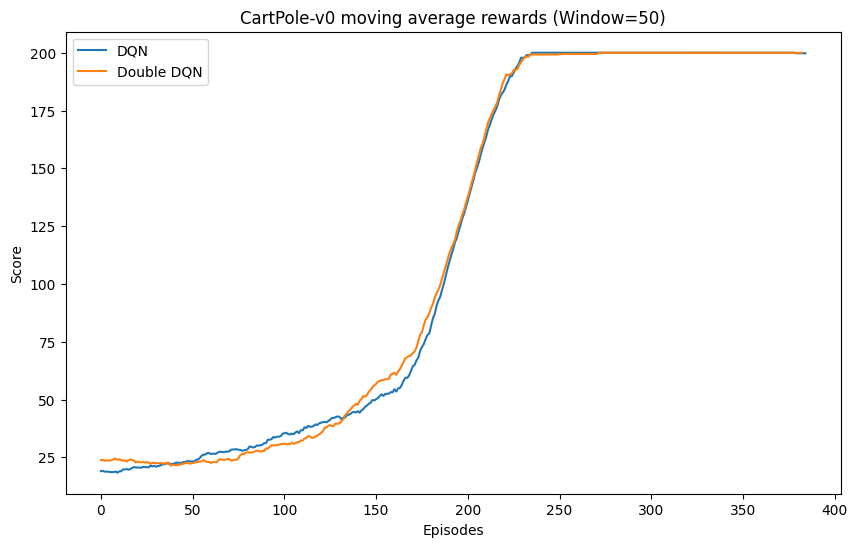

In [13]:
def moving_average(data, window_size=50):
    weights = np.repeat(1.0, window_size) / window_size
    return np.convolve(data, weights, "valid")


plt.figure(figsize=(10, 6))
plt.title("CartPole-v0 moving average rewards (Window=50)")
plt.xlabel("Episodes")
plt.ylabel("Score")
plt.plot(moving_average(all_rewards1[:, 1]), label="DQN")
plt.plot(moving_average(all_rewards2[:, 1]), label="Double DQN")
plt.legend()
plt.show()

**Observation:** Double DQN generally converges more stably and is less prone to sudden performance drops (high variance) in the later stages of training compared to the original DQN.


### 1.3. Playing with the trained DQNs


/data/CiCi/code/learning/uit/.venv/lib/python3.13/site-packages/gymnasium/envs/registration.py:513: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


Total Reward: 200.0


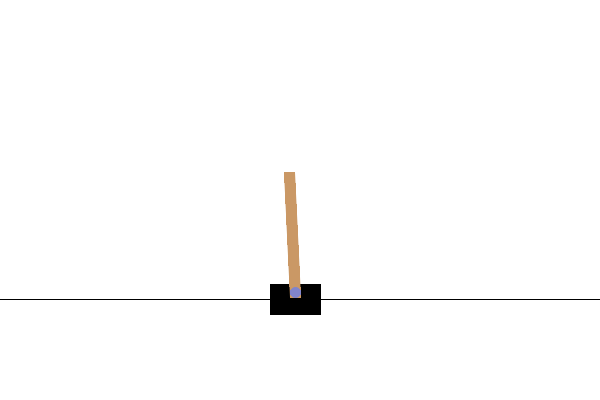

In [21]:
play(dqn_cp, "CartPole-v0")

Total Reward: 200.0


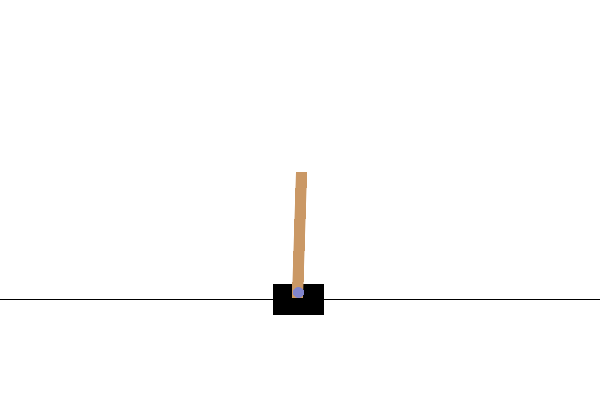

In [22]:
play(double_dqn_cp, "CartPole-v0")

## 2. Solving Mountain Car with Double DQN


### 2.1. Defining new NN class for Mountain Car and Hyperparameters


In [ ]:
class NeuralNetwork2(nn.Module):
    def __init__(self, env):
        super(NeuralNetwork2, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(env.observation_space.shape[0], 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, env.action_space.n),
        )

    def forward(self, state):
        return self.network(state)

    def choose_action(self, state):
        state = torch.tensor((state,), dtype=torch.float32).to(device)
        q_values = self(state)
        best_action = torch.argmax(q_values, dim=1)[0]
        return best_action.detach().cpu().item()

In [49]:
env_mc = gym.make("MountainCar-v0", render_mode="rgb_array")


# Hyperparameters
max_num_steps_mc = 150000
max_epsilon_mc = 1.0
min_epsilon_mc = 0.1
epsilon_decay_intervals_mc = 25000
gamma_mc = 0.99
alpha_mc = 1e-3


memory_size = 100000
min_replay_size = 1000
batch_size = 128

target_update_frequency = 1000

### 2.2. Defining the training loop


In [ ]:
def dqn_training_mc(
    env,
    max_num_steps,
    max_epsilon,
    min_epsilon,
    num_epsilon_decay_intervals,
    gamma,
    lr,
    double=False,
):
    q_net = NeuralNetwork2(env).to(device)
    target_net = NeuralNetwork2(env).to(device)
    target_net.load_state_dict(q_net.state_dict())
    optimizer = torch.optim.Adam(q_net.parameters(), lr=lr)

    memory = fill_memory(env)
    reward_buffer = deque(maxlen=100)

    reward_per_episode = 0.0
    state, info = env.reset()
    all_rewards = []

    for step in range(max_num_steps):
        epsilon = np.interp(
            step, [0, num_epsilon_decay_intervals], [max_epsilon, min_epsilon]
        )

        random_number = np.random.uniform(0, 1)
        if random_number <= epsilon:
            action = env.action_space.sample()
        else:
            action = q_net.choose_action(state)

        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        # Reward shaping for MountainCar: award additional reward based on the velocity achieved and position to encourage the algorithm to explore up the hill
        position, velocity = next_state
        shaped_reward = reward + abs(velocity) * 15

        experience = (state, action, shaped_reward, done, next_state)
        memory.append(experience)
        reward_per_episode += reward  # Store the original reward for tracking

        state = next_state

        if done:
            state, info = env.reset()
            reward_buffer.append(reward_per_episode)
            all_rewards.append((step, reward_per_episode))
            reward_per_episode = 0.0

        # Sample a batch
        experiences = random.sample(memory, batch_size)
        states = torch.tensor([ex[0] for ex in experiences], dtype=torch.float32).to(
            device
        )
        actions = (
            torch.tensor([ex[1] for ex in experiences], dtype=torch.int64)
            .unsqueeze(-1)
            .to(device)
        )
        rewards = (
            torch.tensor([ex[2] for ex in experiences], dtype=torch.float32)
            .unsqueeze(-1)
            .to(device)
        )
        dones = (
            torch.tensor([ex[3] for ex in experiences], dtype=torch.float32)
            .unsqueeze(-1)
            .to(device)
        )
        next_states = torch.tensor(
            [ex[4] for ex in experiences], dtype=torch.float32
        ).to(device)

        if double:
            # using the formulation sample = r + gamma * q(s', argmax q(s',a'))
            next_q_values = q_net(next_states)
            best_actions = next_q_values.argmax(dim=1, keepdim=True)
            target_q_values = target_net(next_states)
            best_target_q_values = torch.gather(
                target_q_values, dim=1, index=best_actions
            )
            targets = rewards + gamma * (1 - dones) * best_target_q_values
        else:
            # using the formulation sample = r + gamma * max q(s',a')
            target_q_values = target_net(next_states)
            max_target_q_values = target_q_values.max(dim=1, keepdim=True)[0]
            targets = rewards + gamma * (1 - dones) * max_target_q_values

        q_values = q_net(states)
        action_q_values = torch.gather(input=q_values, dim=1, index=actions)
        loss = torch.nn.functional.mse_loss(action_q_values, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (step + 1) % target_update_frequency == 0:
            target_net.load_state_dict(q_net.state_dict())

        if (step + 1) % 5000 == 0:
            average_reward = np.mean(reward_buffer) if len(reward_buffer) > 0 else 0
            print(
                f"Episode: {len(all_rewards)} Step: {step+1} Average reward: {average_reward}"
            )

    return np.array(all_rewards), q_net

### 2.3. Training Double DQN for Mountain Car


In [50]:
all_rewards_mc, double_dqn_mc = dqn_training_mc(
    env_mc,
    max_num_steps_mc,
    max_epsilon_mc,
    min_epsilon_mc,
    epsilon_decay_intervals_mc,
    gamma_mc,
    alpha_mc,
    double=True,
)

Episode: 25 Step: 5000 Average reward: -200.0
Episode: 50 Step: 10000 Average reward: -200.0
Episode: 75 Step: 15000 Average reward: -200.0
Episode: 102 Step: 20000 Average reward: -195.88
Episode: 135 Step: 25000 Average reward: -179.45
Episode: 174 Step: 30000 Average reward: -150.93
Episode: 213 Step: 35000 Average reward: -131.71
Episode: 250 Step: 40000 Average reward: -130.29
Episode: 287 Step: 45000 Average reward: -133.19
Episode: 323 Step: 50000 Average reward: -136.58
Episode: 358 Step: 55000 Average reward: -139.35
Episode: 394 Step: 60000 Average reward: -138.85
Episode: 433 Step: 65000 Average reward: -135.12
Episode: 474 Step: 70000 Average reward: -127.32
Episode: 513 Step: 75000 Average reward: -124.21
Episode: 552 Step: 80000 Average reward: -126.0
Episode: 590 Step: 85000 Average reward: -131.25
Episode: 628 Step: 90000 Average reward: -132.14
Episode: 664 Step: 95000 Average reward: -133.6
Episode: 702 Step: 100000 Average reward: -134.03
Episode: 739 Step: 105000 Av

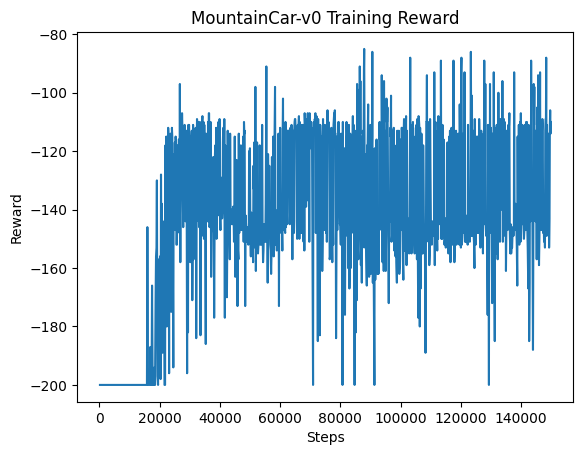

In [51]:
plt.figure()
plt.title("MountainCar-v0 Training Reward")
plt.xlabel("Steps")
plt.ylabel("Reward")
plt.plot(all_rewards_mc[:, 0], all_rewards_mc[:, 1])
plt.show()

### 2.4. "Solving" Mountain Car with the trained Double DQN


There is no exact requirement to actually "solve" the Mountain Car environment. Therefore I will based on the following URL:
https://github.com/openai/gym/wiki/MountainCar-v0,
which states that the environment is considered solved when the agent obtains an average reward of -110.0 over 100 consecutive episodes.


In [52]:
num_of_satisfied_episodes = 0
best_reward = float("-inf")
for i in range(100):
    print(f"Episode {i+1}: ", end="")
    gif, reward = play(double_dqn_mc, "MountainCar-v0", True)
    if reward >= -110.0:
        num_of_satisfied_episodes += 1
    if reward > best_reward:
        best_reward = reward
        best_gif = gif

Episode 1: Total Reward: -89.0
Episode 2: Total Reward: -109.0
Episode 3: Total Reward: -146.0
Episode 4: Total Reward: -86.0
Episode 5: Total Reward: -126.0
Episode 6: Total Reward: -83.0
Episode 7: Total Reward: -83.0
Episode 8: Total Reward: -90.0
Episode 9: Total Reward: -83.0
Episode 10: Total Reward: -151.0
Episode 11: Total Reward: -135.0
Episode 12: Total Reward: -92.0
Episode 13: Total Reward: -111.0
Episode 14: Total Reward: -85.0
Episode 15: Total Reward: -157.0
Episode 16: Total Reward: -100.0
Episode 17: Total Reward: -147.0
Episode 18: Total Reward: -109.0
Episode 19: Total Reward: -109.0
Episode 20: Total Reward: -110.0
Episode 21: Total Reward: -147.0
Episode 22: Total Reward: -85.0
Episode 23: Total Reward: -83.0
Episode 24: Total Reward: -145.0
Episode 25: Total Reward: -150.0
Episode 26: Total Reward: -152.0
Episode 27: Total Reward: -84.0
Episode 28: Total Reward: -109.0
Episode 29: Total Reward: -155.0
Episode 30: Total Reward: -145.0
Episode 31: Total Reward: -83.

Total 58/100 episodes satisfied the requirement of reward >= -110.0
Best reward achieved: -83.0


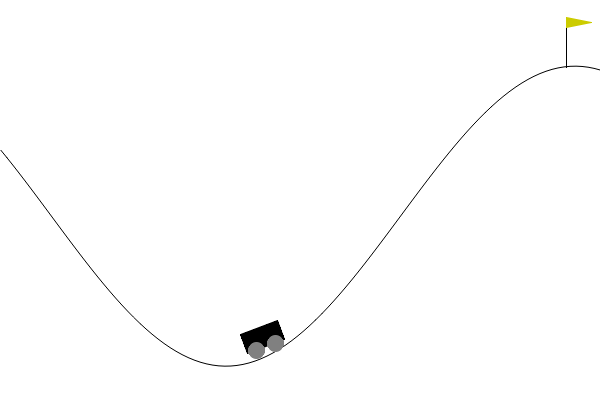

In [53]:
print(
    f"Total {num_of_satisfied_episodes}/100 episodes satisfied the requirement of reward >= -110.0"
)
print(f"Best reward achieved: {best_reward}")
best_gif